# Description

Training for analyzing Octopus-slabs database with Pandas


# Page usage

* Checking how many entries we have with a certain filter.  


# Loading library

In [1]:
import pandas as pd
import octopus_slabs
from octopus_slabs.Libs.libPlotting import IndexFunctional
import os
import matplotlib.pyplot as plt
import numpy as np
OctopusData=os.environ["QuantumLaPruns"]
OctopusSources=os.environ["QuantumLaPsources"]
print(OctopusData, OctopusSources)

/home/thibault.derrien/Documents/octopus.data /home/thibault.derrien/Documents/octopus-slabs


# Going to the folder containing the database

In [2]:
# Localhost
# DatabasePath=OctopusData+"/03-Bulk3D/Si-1x1x1-k-24x24x1-Mesh0.434637008855-Mesh0.434637008855-T0e0-TB09/SingleColorSummary"

# BIATRI-SRV TB09 from backups (Draco, etc)
# DatabasePath=OctopusData+"/03-Bulk3D/01-ImportingTB09"

DatabasePath=OctopusData+"/03-Bulk3D/"
# DatabasePath=OctopusData+"/09-Au/"
%cd $DatabasePath

/home/thibault.derrien/Documents/octopus.data/03-Bulk3D


# Database loading and quick analysis

In [3]:
data=pd.read_csv("SiComplete-2021-12-19-BiatriSrv-v2.2.1-WithToleranceOnField-WithAll.csv", "\t", header=2)
# data=pd.read_csv("2021-02-25-Au-AllData-Database-v2.1.2.csv", "\t", header=2)
datafull=data
data.describe(include="all")
data.dtypes


##JobID                         float64
RunDate                         float64
kgrid                           float64
realmesh                        float64
lambda1                         float64
tau1                            float64
Efield1                         float64
PolarizationAngle               float64
CEP1                            float64
lambda2                         float64
tau2                            float64
Efield2                         float64
CEP2                            float64
delay                           float64
CrossPolar                      float64
TheoryLevel                     float64
InducedFields                   float64
ProbeFieldAmplitude_AU          float64
ProbeFieldDelay_s               float64
Functional                      float64
FrozenHxc                       float64
MoveIon                         float64
NeMax                           float64
NeFinal                         float64
VirtualOscillations             float64


# Database filtering

In [4]:
data=datafull
data=data[data.Functional==IndexFunctional["LDA"]] #0: LDA, #3: TB09, #2: GGA, #1: MGGA
data=data[data.kgrid>=24]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2574,526584.0,20210930.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.376991,0.0,2.656000e-06,...,0.049758,0.456884,1.068931e+15,2.233046e+27,1.601389e+41,1.601324e+41,1.0,0.0,1250.0,1153.010893
2575,516077.0,20210912.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.157080,0.0,2.656000e-06,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893
2576,520136.0,20210919.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.314159,0.0,2.656000e-06,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893
2577,520137.0,20210919.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.471239,0.0,2.656000e-06,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893


In [5]:
#data=data[data.CEP1==0]; 
#data=data[data.STH==3]; 
data=data[data.InducedFields==0]
data

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
0,4802615.0,20180508.0,24.0,0.434637,8.000000e-07,2.000000e-14,8.000000e+08,0.000000,0.0,8.000000e-07,...,0.006785,0.037806,-2.567970e+13,2.810224e+26,1.404822e+40,1.405112e+40,3.0,2.0,2262.5,937.147441
1,5882467.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.010887,0.042221,-3.133202e+14,4.756259e+26,1.570724e+40,1.585420e+40,3.0,2.0,3087.5,1350.561171
2,5882393.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.012325,0.041614,-1.059148e+14,4.437532e+26,1.477840e+40,1.479177e+40,3.0,2.0,3175.0,1350.561171
3,5882390.0,20180904.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.600000e-06,...,0.006391,0.030018,-4.980174e+13,2.515133e+26,8.378722e+39,8.383777e+39,3.0,2.0,3262.5,1350.561171
4,5882469.0,20180909.0,24.0,0.434637,8.000000e-07,3.000000e-14,7.000000e+08,0.000000,0.0,1.030000e-06,...,0.014642,0.048031,-3.211832e+14,6.672187e+26,2.200183e+40,2.224062e+40,3.0,2.0,3100.0,1350.561171
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2574,526584.0,20210930.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.376991,0.0,2.656000e-06,...,0.049758,0.456884,1.068931e+15,2.233046e+27,1.601389e+41,1.601324e+41,1.0,0.0,1250.0,1153.010893
2575,516077.0,20210912.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.157080,0.0,2.656000e-06,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.0,1153.010893
2576,520136.0,20210919.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.314159,0.0,2.656000e-06,...,0.000000,0.465246,1.936705e+14,2.169291e+27,1.555847e+41,1.555605e+41,1.0,0.0,1500.0,1153.010893
2577,520137.0,20210919.0,40.0,0.434637,2.656000e-06,1.394500e-14,3.000000e+09,0.471239,0.0,2.656000e-06,...,0.000000,0.441240,2.298413e+14,2.347336e+27,1.683482e+41,1.683282e+41,1.0,0.0,1500.0,1153.010893


In [6]:
data=data.sort_values(["lambda1", "tau1", "Efield1", "Efield2", "PolarizationAngle", "kgrid", "realmesh"], ascending=True)
datafull=data

In [7]:
datafull

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
163,5109637.0,20180601.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+08,0.0,0.0,2.000000e-07,...,8.262708e-04,0.009809,-2.583857e+11,3.957254e+25,1.973568e+39,1.978627e+39,3.0,2.0,3812.5,854.407455
1469,8715191.0,20190625.0,24.0,0.434637,2.000000e-07,2.000000e-14,5.000000e+08,0.0,0.0,2.000000e-07,...,1.952543e-02,0.231439,-7.046549e+12,9.323506e+26,4.661432e+40,4.661753e+40,3.0,2.0,3125.0,854.407455
1524,8918119.0,20190708.0,24.0,0.434637,2.000000e-07,2.000000e-14,7.500000e+08,0.0,0.0,2.000000e-07,...,4.079272e-02,0.483535,-9.950841e+12,1.940461e+27,9.701183e+40,9.702303e+40,3.0,2.0,3125.0,854.407455
312,5027620.0,20180524.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.000000e+09,0.0,0.0,2.000000e-07,...,6.555565e-02,0.776664,5.249025e+12,3.099319e+27,1.549393e+41,1.549659e+41,3.0,2.0,2975.0,854.407455
1414,8918121.0,20190709.0,24.0,0.434637,2.000000e-07,2.000000e-14,1.500000e+09,0.0,0.0,2.000000e-07,...,1.123667e-01,1.334319,-1.315329e+13,5.230000e+27,2.614998e+41,2.615000e+41,3.0,2.0,3125.0,854.407455
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,10050046.0,20191101.0,24.0,0.434637,4.100000e-06,2.000000e-14,5.000000e+08,0.0,0.0,4.100000e-06,...,3.690789e-07,0.000040,4.772506e+13,3.844612e+27,2.465914e+35,1.922306e+41,3.0,2.0,3750.0,1392.217365
1739,17608855.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,5.000000e+08,0.0,0.0,6.400000e-06,...,2.562692e-06,0.000037,9.126449e+13,5.590327e+24,7.342516e+34,9.317212e+37,3.0,2.0,7750.0,3363.042231
1736,17638129.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,7.500000e+08,0.0,0.0,6.400000e-06,...,2.733345e-05,0.000141,7.494698e+13,1.337371e+25,1.286704e+37,2.228952e+38,3.0,2.0,7625.0,3363.042231
1712,17608858.0,20200127.0,24.0,0.434637,6.400000e-06,6.000000e-14,1.000000e+09,0.0,0.0,6.400000e-06,...,4.830202e-04,0.002872,-5.717343e+12,3.822728e+25,2.664830e+38,6.371213e+38,3.0,2.0,7500.0,3363.042231


In [8]:
from octopus_slabs.Libs.libPlotting import PulseTypeID
print(PulseTypeID['SinSquared'])
datatmp=datafull
# datatmp=data[data.PolarizationAngle>0]
# datatmp=datatmp[np.fabs(datatmp.lambda1-1.367968e-6)<1e-9] #Bicolor runs
# datatmp=datatmp[np.fabs(datatmp.lambda1-800e-9)<1e-9]
datatmp=datatmp[np.fabs(datatmp.lambda1-2.65625e-6)<1e-9] #Kozak 2000 nm
datatmp=datatmp[datatmp.Efield2==0]
datatmp=datatmp[datatmp.Efield1==3E9]
datatmp=datatmp[datatmp.CEP1==0]
datatmp=datatmp[datatmp.STH==PulseTypeID['SinSquared']]
# datatmp=datatmp[np.fabs(datatmp.tau1-30E-15)<1E-15]
datatmp=datatmp[datatmp.FrozenHxc==0]
# datatmp=datatmp[datatmp.PolarizationAngle==0]
data2 = datatmp

# plt.loglog(Efield, Wpi, "v")
# plt.semilogx(JobID, RunDate_t)
# datafield1=datatmp[datatmp.Efield1==3E9]
# datafield2=datatmp[datatmp.Efield1==9E9]

1


In [9]:
datatmp

,##JobID,RunDate,kgrid,realmesh,lambda1,tau1,Efield1,PolarizationAngle,CEP1,lambda2,...,ExchangeEnergy_afterpulse_eV,PoyntingEnergyFinal_eV,Eext_peak_V_m,N_exc_afterpulse,Wpi,Wpi_afterpulse,STH,RiseCycles,FinalTime,CaptureTime
2231,441931.0,20210429.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477183,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2260,460293.0,20210531.0,24.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477183,-1.110208e+15,1.973202e+27,1.416821e+41,1.414989e+41,1.0,0.0,3266.25,1153.010893
2532,499932.0,20210804.0,32.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477509,-7.741582e+14,1.975252e+27,1.417607e+41,1.416459e+41,1.0,0.0,2750.00,1153.010893
2491,498934.0,20210803.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477130,7.007967e+14,1.974000e+27,1.415733e+41,1.415561e+41,1.0,0.0,1375.00,1153.010893
2489,513084.0,20210902.0,48.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.000000,0.0,0.000003,...,0.000000,0.477132,-1.091467e+15,1.974034e+27,1.417301e+41,1.415585e+41,1.0,0.0,3266.25,1153.010893
2484,527844.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.062832,0.0,0.000003,...,0.045699,0.477451,1.054200e+15,1.986689e+27,1.424753e+41,1.424660e+41,1.0,0.0,1250.00,1153.010893
2482,528466.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.125664,0.0,0.000003,...,0.045713,0.476599,1.057210e+15,2.018731e+27,1.447718e+41,1.447638e+41,1.0,0.0,1250.00,1153.010893
2575,516077.0,20210912.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.157080,0.0,0.000003,...,0.000000,0.475732,1.403247e+14,2.038333e+27,1.461907e+41,1.461694e+41,1.0,0.0,1500.00,1153.010893
2578,528467.0,20210929.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.188496,0.0,0.000003,...,0.046283,0.474552,1.061637e+15,2.059679e+27,1.477081e+41,1.477002e+41,1.0,0.0,1250.00,1153.010893
2573,528468.0,20210930.0,40.0,0.434637,0.000003,1.394500e-14,3.000000e+09,0.251327,0.0,0.000003,...,0.047047,0.471900,1.065911e+15,2.113984e+27,1.516003e+41,1.515944e+41,1.0,0.0,1250.00,1153.010893


In [10]:
datatmp.PolarizationAngle/np.pi

2231    0.00
2260    0.00
2532    0.00
2491    0.00
2489    0.00
2484    0.02
2482    0.04
2575    0.05
2578    0.06
2573    0.08
2576    0.10
2574    0.12
2485    0.14
2577    0.15
2483    0.16
2428    0.25
2454    0.25
2487    0.25
2530    0.25
2181    0.00
2202    0.00
2199    0.02
2203    0.04
2190    0.05
2148    0.06
2195    0.08
2189    0.10
2193    0.12
2197    0.14
2183    0.15
2206    0.16
2187    0.20
2205    0.24
2185    0.25
2198    0.25
Name: PolarizationAngle, dtype: float64

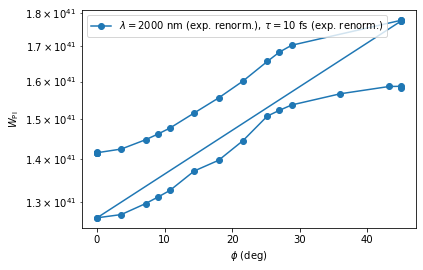

In [11]:
plt.figure()
plt.semilogy(data2.PolarizationAngle*180/np.pi, data2.Wpi_afterpulse, "-o", label=r"$\lambda=2000$ nm (exp. renorm.), $\tau=$10 fs (exp. renorm.)")
# plt.xlabel(r"$E_{peak}$ (V/m)")
plt.xlabel(r"$\phi$ (deg)")
plt.ylabel(r"$W_{\mathrm{PI}}$")
plt.legend()